# Tarea 3 — EDA con Spark

**Proyecto Integrador — Minería de Datos Masivos**

Este notebook corresponde al análisis exploratorio de los datos limpios de contrataciones públicas SEACE/OCDS.

Los datos fueron previamente descargados, limpiados y transformados por la Persona A.  
Aquí se trabaja exclusivamente sobre las tablas Parquet finales y el EDA se realiza utilizando Apache Spark.

Periodo analizado: enero de 2024 a agosto de 2026.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F

In [2]:
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("SEACE-EDA")
    .config("spark.driver.memory", "8g")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark:", spark.version)
print("Paralelismo:", spark.sparkContext.defaultParallelism)

26/10/04 16:57:11 WARN Utils: Your hostname, willian-pc resolves to a loopback address: 127.0.1.1; using 192.168.18.28 instead (on interface wlo1)
26/10/04 16:57:11 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/04 16:57:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark: 3.5.3
Paralelismo: 8


In [3]:
PROJECT_ROOT = Path.home() / "dm"
DATA_DIR = PROJECT_ROOT / "parquet"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts" / "eda"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print("Datos:", DATA_DIR)
print("Artefactos:", ARTIFACTS_DIR)

Datos: /home/willian/dm/parquet
Artefactos: /home/willian/dm/artifacts/eda


In [4]:
procesos = spark.read.parquet(str(DATA_DIR / "procesos"))
items = spark.read.parquet(str(DATA_DIR / "items"))
postores = spark.read.parquet(str(DATA_DIR / "postores"))
adjudicaciones = spark.read.parquet(str(DATA_DIR / "adjudicaciones"))
contratos = spark.read.parquet(str(DATA_DIR / "contratos"))
entidades = spark.read.parquet(str(DATA_DIR / "entidades"))

In [5]:
tablas = {
    "procesos": procesos,
    "items": items,
    "postores": postores,
    "adjudicaciones": adjudicaciones,
    "contratos": contratos,
    "entidades": entidades,
}

resumen = []

for nombre, df in tablas.items():
    resumen.append({
        "tabla": nombre,
        "filas": df.count(),
        "columnas": len(df.columns),
        "particiones": df.rdd.getNumPartitions(),
    })

pd.DataFrame(resumen)

,tabla,filas,columnas,particiones
0,procesos,209740,47,8
1,items,243699,17,8
2,postores,2493612,5,8
3,adjudicaciones,174908,13,4
4,contratos,153272,16,4
5,entidades,2992,8,1


In [6]:
procesos.select(
    F.min("fecha_pub").alias("fecha_min"),
    F.max("fecha_pub").alias("fecha_max"),
    F.count("*").alias("n_procesos")
).show(truncate=False)

procesos.groupBy("anio_pub") \
    .count() \
    .orderBy("anio_pub") \
    .show()

+-------------------+-------------------+----------+
|fecha_min          |fecha_max          |n_procesos|
+-------------------+-------------------+----------+
|2024-01-02 13:14:00|2026-08-31 23:55:00|209740    |
+-------------------+-------------------+----------+

+--------+-----+
|anio_pub|count|
+--------+-----+
|    2024|80109|
|    2025|79097|
|    2026|50534|
+--------+-----+



In [7]:
procesos.printSchema()

procesos.select(
    "fecha_pub",
    "periodo",
    "entidad",
    "entidad_tipo",
    "entidad_departamento",
    "categoria",
    "procedimiento",
    "estado_proceso",
    "valor_pen_valido",
    "n_postores",
    "n_items"
).show(5, truncate=40)

root
 |-- entidad_id: string (nullable = true)
 |-- release_id: string (nullable = true)
 |-- ocid: string (nullable = true)
 |-- fecha_release: timestamp_ntz (nullable = true)
 |-- proceso_id: string (nullable = true)
 |-- entidad: string (nullable = true)
 |-- titulo: string (nullable = true)
 |-- descripcion: string (nullable = true)
 |-- metodo: string (nullable = true)
 |-- procedimiento: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- fecha_pub: timestamp_ntz (nullable = true)
 |-- fecha_inicio_conv: timestamp_ntz (nullable = true)
 |-- fecha_fin_conv: timestamp_ntz (nullable = true)
 |-- valor_orig: double (nullable = true)
 |-- moneda: string (nullable = true)
 |-- valor_pen: double (nullable = true)
 |-- n_postores_declarado: integer (nullable = true)
 |-- proyecto_id: string (nullable = true)
 |-- info_protegida: boolean (nullable = true)
 |-- archivo_origen: integer (nullable = true)
 |-- mes_pub: integer (nullable = true)
 |-- periodo: string (nullabl

## 1. Evolución temporal de los procesos de contratación

**Pregunta:** ¿Cómo evolucionó mensualmente la cantidad de procesos de contratación pública entre enero de 2024 y agosto de 2026?

Se utiliza `fecha_pub` como referencia temporal y `periodo` (`yyyy-MM`) para realizar la agregación mensual.

In [8]:
procesos_mes = (
    procesos
    .groupBy("periodo")
    .agg(
        F.count("*").alias("n_procesos")
    )
    .orderBy("periodo")
)

procesos_mes.show(40, truncate=False)

+-------+----------+
|periodo|n_procesos|
+-------+----------+
|2024-01|1008      |
|2024-02|4382      |
|2024-03|6340      |
|2024-04|8528      |
|2024-05|8337      |
|2024-06|6941      |
|2024-07|6745      |
|2024-08|6863      |
|2024-09|7164      |
|2024-10|8346      |
|2024-11|7030      |
|2024-12|8425      |
|2025-01|1231      |
|2025-02|4980      |
|2025-03|8199      |
|2025-04|9356      |
|2025-05|3646      |
|2025-06|5880      |
|2025-07|6715      |
|2025-08|7478      |
|2025-09|7707      |
|2025-10|8307      |
|2025-11|7079      |
|2025-12|8519      |
|2026-01|994       |
|2026-02|4884      |
|2026-03|8289      |
|2026-04|7958      |
|2026-05|7853      |
|2026-06|7377      |
|2026-07|6600      |
|2026-08|6579      |
+-------+----------+



In [9]:
procesos_mes_pd = procesos_mes.toPandas()

procesos_mes_pd.head()

,periodo,n_procesos
0,2024-01,1008
1,2024-02,4382
2,2024-03,6340
3,2024-04,8528
4,2024-05,8337


In [10]:
ruta_salida = ARTIFACTS_DIR / "procesos_por_mes.csv"

procesos_mes_pd.to_csv(
    ruta_salida,
    index=False
)

print(f"Guardado en: {ruta_salida}")

Guardado en: /home/willian/dm/artifacts/eda/procesos_por_mes.csv


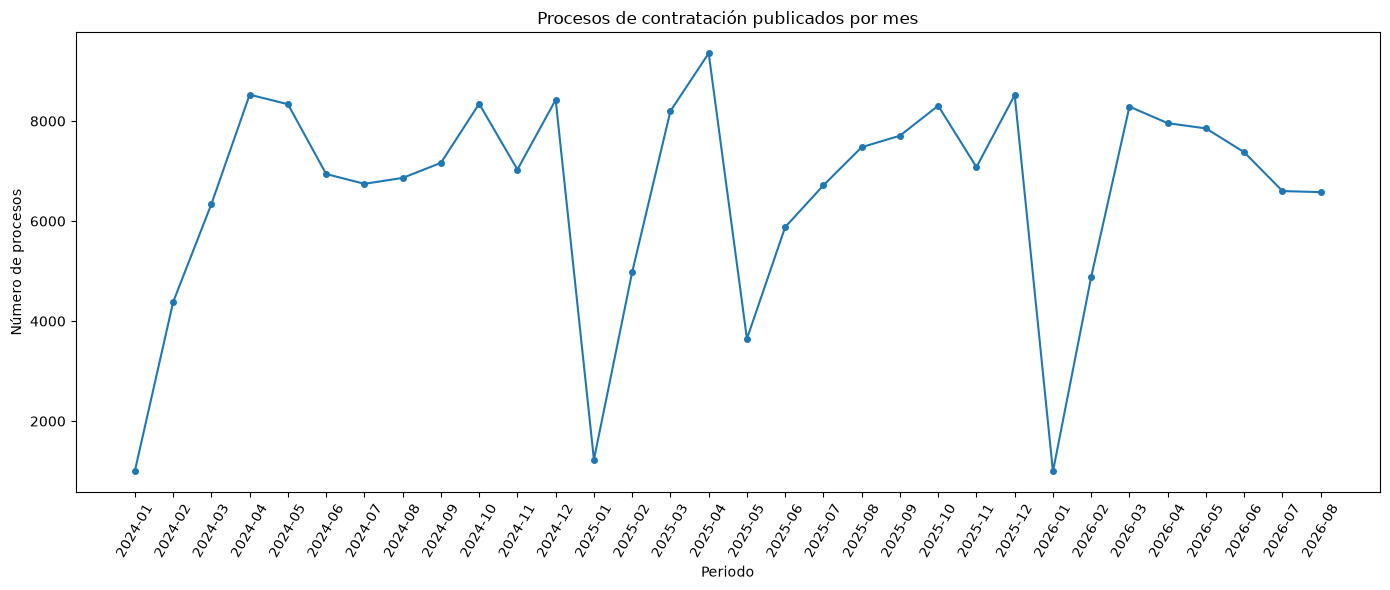

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    procesos_mes_pd["periodo"],
    procesos_mes_pd["n_procesos"],
    marker="o",
    markersize=4
)

ax.set_title("Procesos de contratación publicados por mes")
ax.set_xlabel("Periodo")
ax.set_ylabel("Número de procesos")

ax.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [12]:
procesos_mes_anio = (
    procesos
    .groupBy("mes_pub")
    .pivot("anio_pub")
    .count()
    .orderBy("mes_pub")
)

procesos_mes_anio.show(12)

+-------+----+----+----+
|mes_pub|2024|2025|2026|
+-------+----+----+----+
|      1|1008|1231| 994|
|      2|4382|4980|4884|
|      3|6340|8199|8289|
|      4|8528|9356|7958|
|      5|8337|3646|7853|
|      6|6941|5880|7377|
|      7|6745|6715|6600|
|      8|6863|7478|6579|
|      9|7164|7707|NULL|
|     10|8346|8307|NULL|
|     11|7030|7079|NULL|
|     12|8425|8519|NULL|
+-------+----+----+----+



In [13]:
print("=== Mes con más procesos ===")

procesos_mes.orderBy(
    F.desc("n_procesos")
).show(5)

print("=== Meses con menos procesos ===")

procesos_mes.orderBy(
    F.asc("n_procesos")
).show(5)

=== Mes con más procesos ===
+-------+----------+
|periodo|n_procesos|
+-------+----------+
|2025-04|      9356|
|2024-04|      8528|
|2025-12|      8519|
|2024-12|      8425|
|2024-10|      8346|
+-------+----------+
only showing top 5 rows

=== Meses con menos procesos ===
+-------+----------+
|periodo|n_procesos|
+-------+----------+
|2026-01|       994|
|2024-01|      1008|
|2025-01|      1231|
|2025-05|      3646|
|2024-02|      4382|
+-------+----------+
only showing top 5 rows



### Interpretación

La cantidad mensual de procesos de contratación presenta un patrón estacional visible durante el periodo analizado.

Enero registra sistemáticamente los valores más bajos: 1,008 procesos en 2024, 1,231 en 2025 y 994 en 2026. Por tanto, esta reducción al inicio de cada año parece ser un comportamiento recurrente y no una anomalía específica del dataset.

El cambio más marcado ocurre entre abril y mayo de 2025. Abril de 2025 registra 9,356 procesos, el máximo de toda la serie, mientras que mayo cae a 3,646 procesos, aproximadamente 61% menos que el mes anterior.

Este comportamiento coincide temporalmente con la entrada en vigencia de la Ley General de Contrataciones Públicas (Ley 32069) el 22 de abril de 2025. Sin embargo, la coincidencia temporal no permite afirmar por sí sola que el cambio normativo sea la única causa de la caída. El periodo debe conservarse en el análisis y tratarse como un cambio estructural potencial, no como un error de los datos.

A partir de junio de 2025, el volumen mensual vuelve progresivamente a niveles comparables con los observados en 2024.

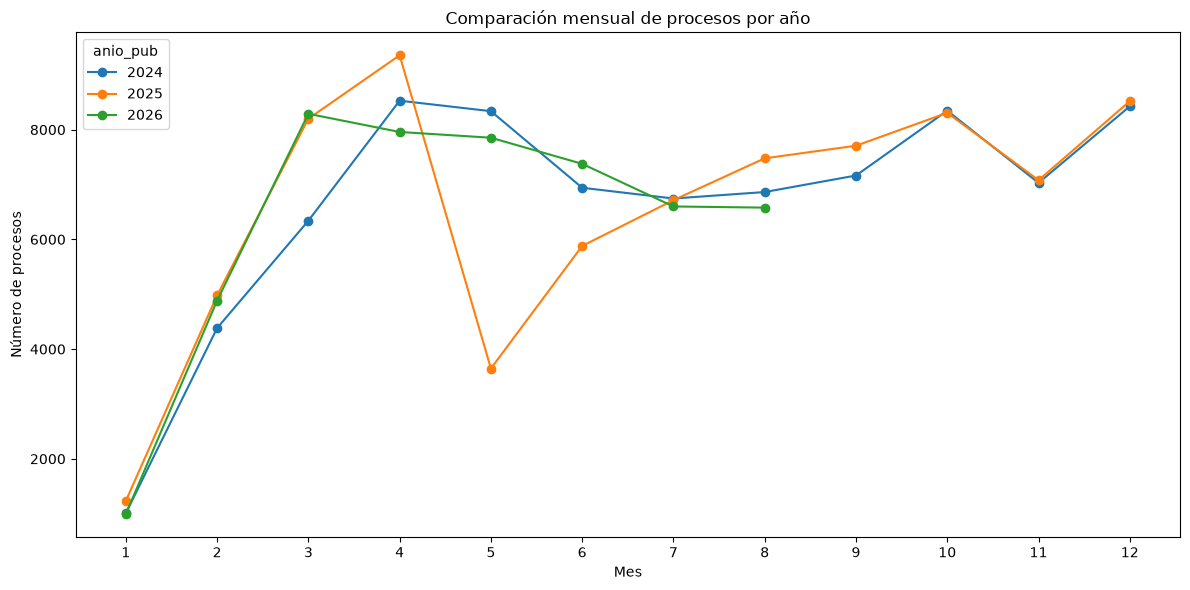

In [14]:
comparacion_mensual_pd = (
    procesos
    .groupBy("mes_pub", "anio_pub")
    .count()
    .orderBy("mes_pub", "anio_pub")
    .toPandas()
)

comparacion_pivot = comparacion_mensual_pd.pivot(
    index="mes_pub",
    columns="anio_pub",
    values="count"
)

comparacion_pivot.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Comparación mensual de procesos por año")
plt.xlabel("Mes")
plt.ylabel("Número de procesos")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [15]:
ruta_salida = ARTIFACTS_DIR / "procesos_mes_anio.csv"

comparacion_mensual_pd.to_csv(
    ruta_salida,
    index=False
)

print(f"Guardado en: {ruta_salida}")

Guardado en: /home/willian/dm/artifacts/eda/procesos_mes_anio.csv


## 2. Distribución por categoría de contratación

**Pregunta:** ¿Qué tipos de contratación concentran la mayor cantidad de procesos en el periodo analizado?

Se analiza la variable `categoria`, que clasifica los procesos en bienes (`goods`), servicios (`services`) y obras (`works`).

In [16]:
procesos_categoria = (
    procesos
    .groupBy("categoria")
    .agg(
        F.count("*").alias("n_procesos")
    )
    .orderBy(F.desc("n_procesos"))
)

procesos_categoria.show(truncate=False)

+---------+----------+
|categoria|n_procesos|
+---------+----------+
|services |91981     |
|goods    |91218     |
|works    |26541     |
+---------+----------+



In [17]:
total_procesos = procesos.count()

procesos_categoria_pct = (
    procesos_categoria
    .withColumn(
        "porcentaje",
        F.round(F.col("n_procesos") / total_procesos * 100, 2)
    )
)

procesos_categoria_pct.show(truncate=False)

+---------+----------+----------+
|categoria|n_procesos|porcentaje|
+---------+----------+----------+
|services |91981     |43.85     |
|goods    |91218     |43.49     |
|works    |26541     |12.65     |
+---------+----------+----------+



In [18]:
procesos_categoria_pd = procesos_categoria_pct.toPandas()

procesos_categoria_pd

,categoria,n_procesos,porcentaje
0,services,91981,43.85
1,goods,91218,43.49
2,works,26541,12.65


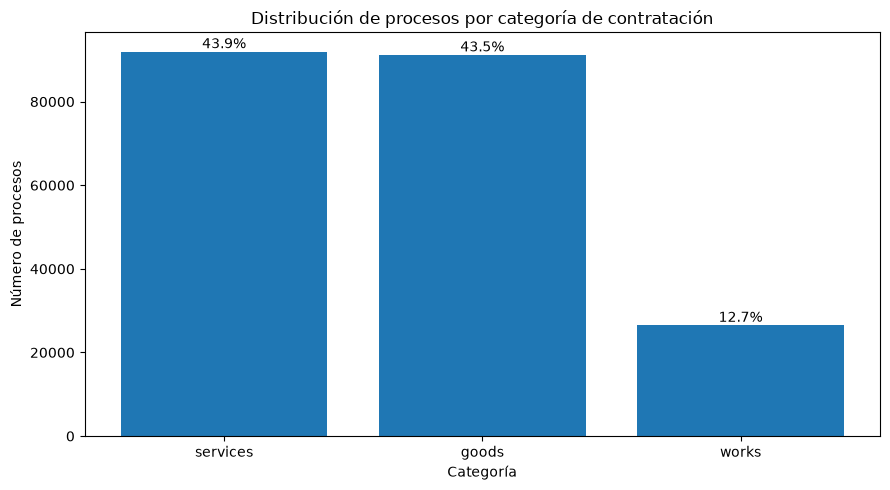

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    procesos_categoria_pd["categoria"],
    procesos_categoria_pd["n_procesos"]
)

ax.set_title("Distribución de procesos por categoría de contratación")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de procesos")

for i, row in procesos_categoria_pd.iterrows():
    ax.text(
        i,
        row["n_procesos"],
        f'{row["porcentaje"]:.1f}%',
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [20]:
ruta_salida = ARTIFACTS_DIR / "procesos_por_categoria.csv"

procesos_categoria_pd.to_csv(
    ruta_salida,
    index=False
)

print(f"Guardado en: {ruta_salida}")

Guardado en: /home/willian/dm/artifacts/eda/procesos_por_categoria.csv


In [21]:
categoria_anio = (
    procesos
    .groupBy("anio_pub", "categoria")
    .agg(
        F.count("*").alias("n_procesos")
    )
    .orderBy("anio_pub", F.desc("n_procesos"))
)

categoria_anio.show(20, truncate=False)

+--------+---------+----------+
|anio_pub|categoria|n_procesos|
+--------+---------+----------+
|2024    |services |35616     |
|2024    |goods    |35500     |
|2024    |works    |8993      |
|2025    |services |34487     |
|2025    |goods    |33902     |
|2025    |works    |10708     |
|2026    |services |21878     |
|2026    |goods    |21816     |
|2026    |works    |6840      |
+--------+---------+----------+



In [22]:
totales_anio = (
    procesos
    .groupBy("anio_pub")
    .agg(F.count("*").alias("total_anio"))
)

categoria_anio_pct = (
    categoria_anio
    .join(totales_anio, "anio_pub")
    .withColumn(
        "porcentaje",
        F.round(
            F.col("n_procesos") / F.col("total_anio") * 100,
            2
        )
    )
    .orderBy("anio_pub", F.desc("n_procesos"))
)

categoria_anio_pct.show(20, truncate=False)

+--------+---------+----------+----------+----------+
|anio_pub|categoria|n_procesos|total_anio|porcentaje|
+--------+---------+----------+----------+----------+
|2024    |services |35616     |80109     |44.46     |
|2024    |goods    |35500     |80109     |44.31     |
|2024    |works    |8993      |80109     |11.23     |
|2025    |services |34487     |79097     |43.6      |
|2025    |goods    |33902     |79097     |42.86     |
|2025    |works    |10708     |79097     |13.54     |
|2026    |services |21878     |50534     |43.29     |
|2026    |goods    |21816     |50534     |43.17     |
|2026    |works    |6840      |50534     |13.54     |
+--------+---------+----------+----------+----------+



### Interpretación

La distribución de los procesos por categoría muestra una composición relativamente equilibrada entre servicios y bienes.

Durante todo el periodo analizado, los servicios representan el 43.85% de los procesos y los bienes el 43.49%, mientras que las obras concentran el 12.65%.

Esta estructura se mantiene bastante estable entre años. En 2024, servicios y bienes representaban 44.46% y 44.31%, respectivamente. En 2025 y 2026 ambos continúan cerca del 43%.

El cambio más visible se encuentra en la categoría de obras, que pasa de 11.23% en 2024 a 13.54% en 2025 y mantiene ese mismo porcentaje en 2026.

Por tanto, no se observa un cambio drástico en la composición general de las contrataciones, aunque sí un incremento moderado del peso relativo de las obras a partir de 2025.

Dado que 2026 solo incluye información hasta agosto, la comparación entre años se realiza principalmente mediante proporciones y no mediante cantidades absolutas.

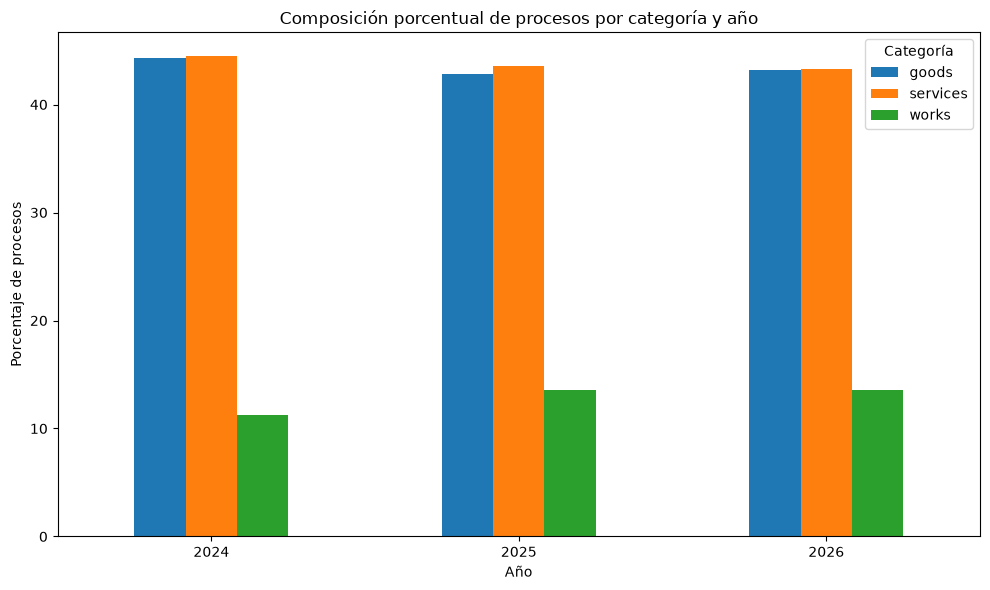

In [23]:
categoria_anio_pd = categoria_anio_pct.toPandas()

categoria_pivot = categoria_anio_pd.pivot(
    index="anio_pub",
    columns="categoria",
    values="porcentaje"
)

categoria_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Composición porcentual de procesos por categoría y año")
plt.xlabel("Año")
plt.ylabel("Porcentaje de procesos")
plt.xticks(rotation=0)
plt.legend(title="Categoría")
plt.tight_layout()
plt.show()

In [24]:
ruta_salida = ARTIFACTS_DIR / "categoria_por_anio.csv"

categoria_anio_pd.to_csv(
    ruta_salida,
    index=False
)

print(f"Guardado en: {ruta_salida}")

Guardado en: /home/willian/dm/artifacts/eda/categoria_por_anio.csv


## 3. Procedimientos de contratación más frecuentes

**Pregunta:** ¿Qué procedimientos concentran la mayor cantidad de procesos de contratación pública?

Se utiliza la variable `procedimiento`, que contiene el tipo específico de procedimiento de contratación.

In [25]:
procedimientos = (
    procesos
    .groupBy("procedimiento")
    .agg(
        F.count("*").alias("n_procesos")
    )
    .orderBy(F.desc("n_procesos"))
)

procedimientos.show(20, truncate=False)

+----------------------------------------------------------------------+----------+
|procedimiento                                                         |n_procesos|
+----------------------------------------------------------------------+----------+
|Adjudicación Simplificada                                             |61823     |
|Licitación Pública Abreviada                                          |29947     |
|Concurso Público Abreviado                                            |26777     |
|Subasta Inversa Electrónica                                           |24102     |
|Comparación de Precios                                                |13919     |
|Licitación Pública                                                    |13180     |
|Contratación Directa                                                  |11488     |
|Regímen Especial                                                      |5846      |
|Concurso Público                                                      |5702

In [26]:
procedimientos_pct = (
    procedimientos
    .withColumn(
        "porcentaje",
        F.round(
            F.col("n_procesos") / total_procesos * 100,
            2
        )
    )
)

procedimientos_pct.show(20, truncate=False)

+----------------------------------------------------------------------+----------+----------+
|procedimiento                                                         |n_procesos|porcentaje|
+----------------------------------------------------------------------+----------+----------+
|Adjudicación Simplificada                                             |61823     |29.48     |
|Licitación Pública Abreviada                                          |29947     |14.28     |
|Concurso Público Abreviado                                            |26777     |12.77     |
|Subasta Inversa Electrónica                                           |24102     |11.49     |
|Comparación de Precios                                                |13919     |6.64      |
|Licitación Pública                                                    |13180     |6.28      |
|Contratación Directa                                                  |11488     |5.48      |
|Regímen Especial                                 

In [ ]:
procedimiento_anio = (
    procesos
    .groupBy("anio_pub", "procedimiento")
    .agg(
        F.count("*").alias("n_procesos")
    )
)

from pyspark.sql.window import Window

w = Window.partitionBy("anio_pub").orderBy(F.desc("n_procesos"))

top_procedimientos_anio = (
    procedimiento_anio
    .withColumn("ranking", F.row_number().over(w))
    .filter(F.col("ranking") <= 10)
    .orderBy("anio_pub", "ranking")
)

top_procedimientos_anio.show(30, truncate=False)

### Interpretación

La distribución de los procedimientos de contratación cambia de manera importante a lo largo del periodo analizado.

En 2024, la **Adjudicación Simplificada** concentraba 46,003 procesos, aproximadamente el 57% del total anual, convirtiéndose ampliamente en el procedimiento dominante.

En 2025 la estructura cambia. La Adjudicación Simplificada disminuye a 15,727 procesos, mientras aparecen con gran peso la **Licitación Pública Abreviada** (15,719) y el **Concurso Público Abreviado** (13,648). Para 2026, estos dos procedimientos pasan a ocupar el primer y segundo lugar, respectivamente.

Este cambio coincide con la entrada en vigencia de la Ley General de Contrataciones Públicas (Ley 32069) en abril de 2025, a partir de la cual aparecen nuevos procedimientos en los datos. Por ello, la comparación entre años no debe interpretarse únicamente como una variación en las preferencias de contratación de las entidades, sino también como un cambio en el régimen y en la clasificación de los procedimientos.

A nivel global, la Adjudicación Simplificada sigue siendo el procedimiento más frecuente del periodo completo (29.48%), pero esta cifra combina dos contextos normativos distintos y oculta el fuerte cambio ocurrido desde 2025.

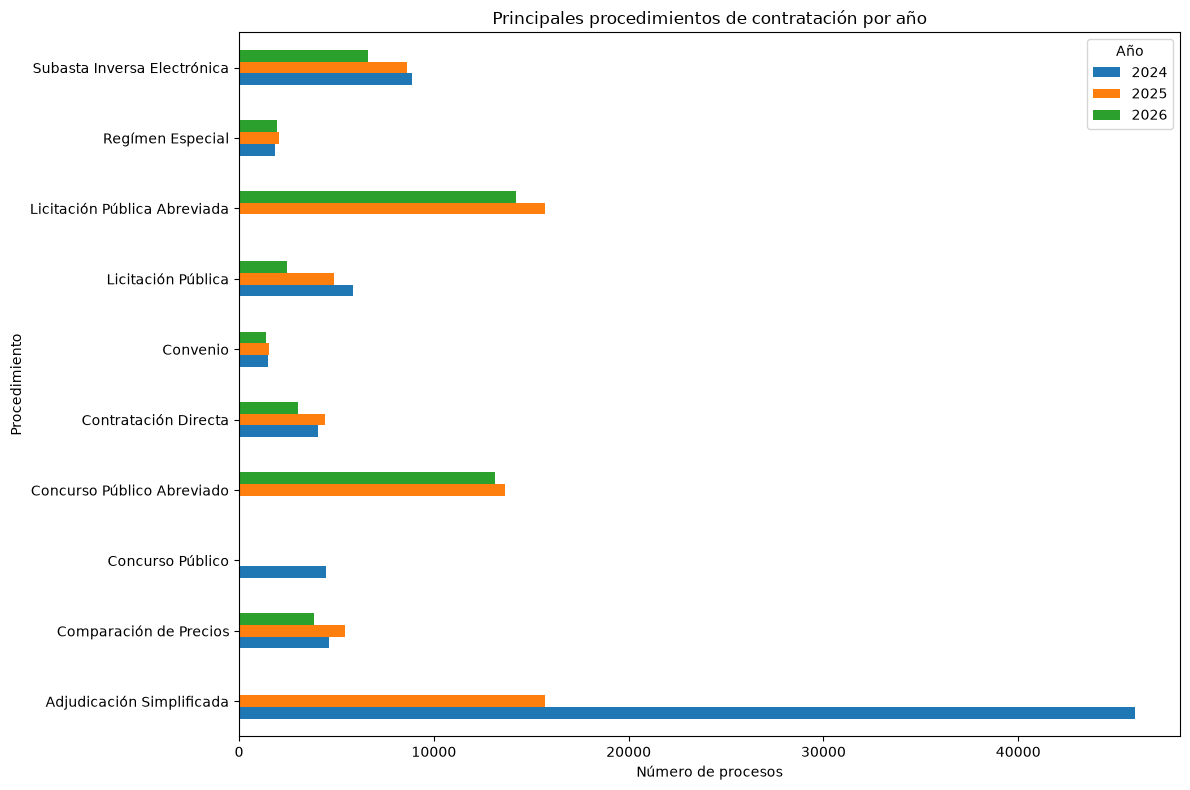

In [28]:
top_proc_pd = top_procedimientos_anio.toPandas()

pivot_proc = top_proc_pd.pivot(
    index="procedimiento",
    columns="anio_pub",
    values="n_procesos"
).fillna(0)

# Nos quedamos con los procedimientos más relevantes en el conjunto
top_globales = (
    procedimientos
    .limit(10)
    .select("procedimiento")
    .toPandas()["procedimiento"]
    .tolist()
)

pivot_proc_top = pivot_proc.loc[
    pivot_proc.index.intersection(top_globales)
]

pivot_proc_top.plot(
    kind="barh",
    figsize=(12, 8)
)

plt.title("Principales procedimientos de contratación por año")
plt.xlabel("Número de procesos")
plt.ylabel("Procedimiento")
plt.legend(title="Año")
plt.tight_layout()
plt.show()

In [29]:
top_proc_pd.to_csv(
    ARTIFACTS_DIR / "top_procedimientos_por_anio.csv",
    index=False
)

In [30]:
procesos_departamento = (
    procesos
    .groupBy("entidad_departamento")
    .agg(
        F.count("*").alias("n_procesos"),
        F.countDistinct("entidad_id").alias("n_entidades")
    )
    .orderBy(F.desc("n_procesos"))
)

procesos_departamento.show(25, truncate=False)

+--------------------+----------+-----------+
|entidad_departamento|n_procesos|n_entidades|
+--------------------+----------+-----------+
|LIMA                |62796     |477        |
|CUSCO               |17847     |166        |
|ANCASH              |11935     |220        |
|PUNO                |9970      |158        |
|JUNIN               |8650      |179        |
|AREQUIPA            |8458      |142        |
|AYACUCHO            |7982      |160        |
|CAJAMARCA           |7802      |180        |
|LA LIBERTAD         |7724      |133        |
|APURIMAC            |7164      |118        |
|PIURA               |6878      |103        |
|HUANUCO             |6060      |126        |
|LORETO              |4757      |86         |
|ICA                 |4453      |68         |
|SAN MARTIN          |4397      |114        |
|HUANCAVELICA        |4381      |136        |
|UCAYALI             |4077      |50         |
|MOQUEGUA            |3985      |38         |
|LAMBAYEQUE          |3976      |6

In [31]:
procesos_departamento_pct = (
    procesos_departamento
    .withColumn(
        "porcentaje_procesos",
        F.round(
            F.col("n_procesos") / total_procesos * 100,
            2
        )
    )
)

procesos_departamento_pct.show(25, truncate=False)

+--------------------+----------+-----------+-------------------+
|entidad_departamento|n_procesos|n_entidades|porcentaje_procesos|
+--------------------+----------+-----------+-------------------+
|LIMA                |62796     |477        |29.94              |
|CUSCO               |17847     |166        |8.51               |
|ANCASH              |11935     |220        |5.69               |
|PUNO                |9970      |158        |4.75               |
|JUNIN               |8650      |179        |4.12               |
|AREQUIPA            |8458      |142        |4.03               |
|AYACUCHO            |7982      |160        |3.81               |
|CAJAMARCA           |7802      |180        |3.72               |
|LA LIBERTAD         |7724      |133        |3.68               |
|APURIMAC            |7164      |118        |3.42               |
|PIURA               |6878      |103        |3.28               |
|HUANUCO             |6060      |126        |2.89               |
|LORETO   

### Interpretación

La actividad de contratación presenta una fuerte concentración en entidades con sede en Lima.

Lima reúne 62,796 procesos, equivalentes al 29.94% del total analizado. Le siguen Cusco con 8.51% y Áncash con 5.69%. A partir de estos departamentos, la participación individual disminuye considerablemente.

Sin embargo, esta concentración no debe interpretarse directamente como concentración geográfica de la ejecución del gasto. La variable `entidad_departamento` representa la sede de la entidad contratante y no necesariamente el lugar donde se ejecuta la obra, se presta el servicio o se entregan los bienes.

Parte de la concentración observada puede explicarse también por la cantidad de entidades ubicadas en cada departamento. Por ello, además del número total de procesos, es conveniente analizar cuántos procesos corresponden en promedio a cada entidad.

In [32]:
actividad_departamento = (
    procesos_departamento_pct
    .withColumn(
        "procesos_por_entidad",
        F.round(
            F.col("n_procesos") / F.col("n_entidades"),
            2
        )
    )
    .orderBy(F.desc("procesos_por_entidad"))
)

actividad_departamento.show(25, truncate=False)

+--------------------+----------+-----------+-------------------+--------------------+
|entidad_departamento|n_procesos|n_entidades|porcentaje_procesos|procesos_por_entidad|
+--------------------+----------+-----------+-------------------+--------------------+
|CALLAO              |3895      |28         |1.86               |139.11              |
|LIMA                |62796     |477        |29.94              |131.65              |
|CUSCO               |17847     |166        |8.51               |107.51              |
|MOQUEGUA            |3985      |38         |1.9                |104.87              |
|TACNA               |3704      |42         |1.77               |88.19               |
|MADRE DE DIOS       |1736      |21         |0.83               |82.67               |
|UCAYALI             |4077      |50         |1.94               |81.54               |
|PIURA               |6878      |103        |3.28               |66.78               |
|ICA                 |4453      |68        

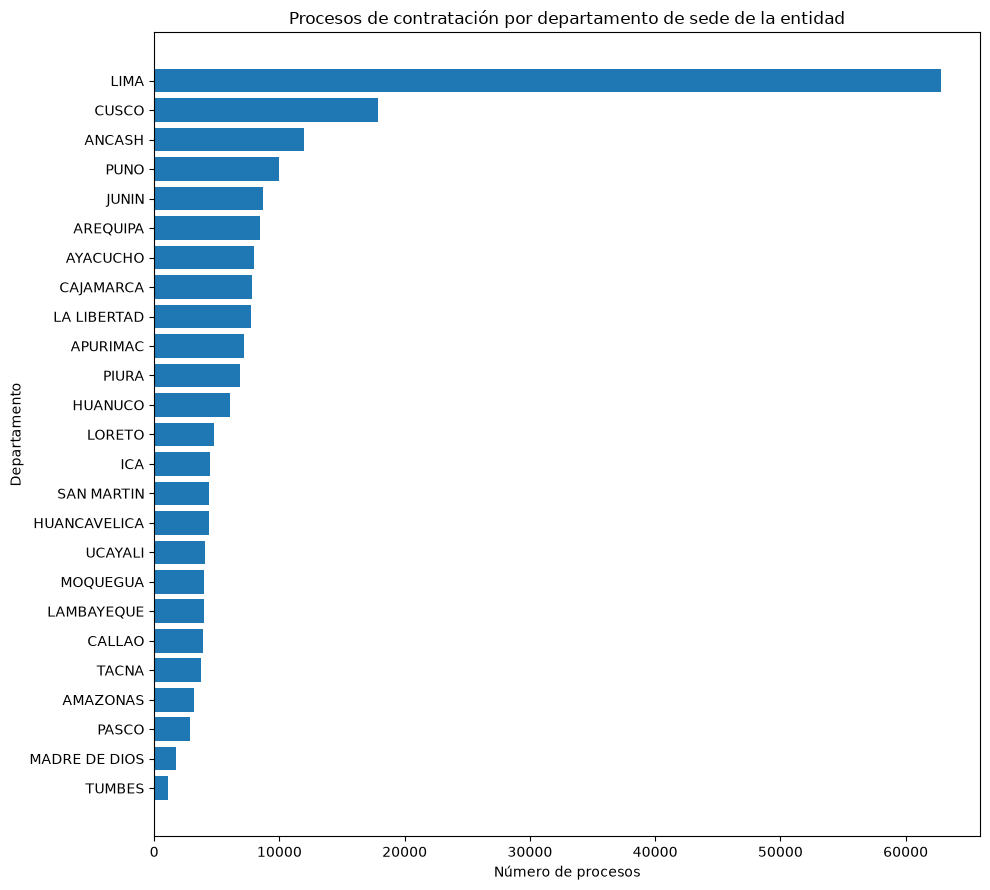

In [33]:
departamentos_pd = procesos_departamento_pct.toPandas()

departamentos_plot = (
    departamentos_pd
    .sort_values("n_procesos", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 9))

ax.barh(
    departamentos_plot["entidad_departamento"],
    departamentos_plot["n_procesos"]
)

ax.set_title("Procesos de contratación por departamento de sede de la entidad")
ax.set_xlabel("Número de procesos")
ax.set_ylabel("Departamento")

plt.tight_layout()
plt.show()

In [34]:
procesos_departamento_pct.toPandas().to_csv(
    ARTIFACTS_DIR / "procesos_por_departamento.csv",
    index=False
)

### Interpretación complementaria

Al normalizar el número de procesos por la cantidad de entidades contratantes, el ranking territorial cambia.

Callao presenta el mayor promedio, con 139.11 procesos por entidad, seguido de Lima con 131.65, Cusco con 107.51 y Moquegua con 104.87.

Esto indica que la concentración observada en Lima no se explica únicamente por la gran cantidad de entidades con sede allí. Algunas regiones con muchas menos entidades también presentan una elevada actividad promedio por institución.

Por ejemplo, Callao registra solo 28 entidades, pero alcanza el mayor promedio de procesos por entidad. Moquegua también destaca con 38 entidades y más de 100 procesos por entidad en promedio.

Por tanto, conviene distinguir entre dos dimensiones:
- **volumen total de procesos**, donde Lima domina ampliamente;
- **intensidad promedio por entidad**, donde Callao ocupa el primer lugar.

Estas cifras describen la actividad de las entidades según su sede administrativa y no la localización geográfica donde se ejecutan las contrataciones.

## 5. Distribución de los montos referenciales

**Pregunta:** ¿Cómo se distribuyen los valores referenciales de los procesos de contratación y qué diferencias existen entre categorías?

Se utiliza `valor_pen_valido`, que contiene el monto referencial en soles excluyendo los valores cero tratados como información no disponible.

In [35]:
montos_validos = procesos.filter(
    F.col("valor_pen_valido").isNotNull()
)

n_total = procesos.count()
n_validos = montos_validos.count()

print("Procesos totales:", n_total)
print("Procesos con monto válido:", n_validos)
print(
    "Cobertura:",
    round(n_validos / n_total * 100, 2),
    "%"
)

Procesos totales: 209740
Procesos con monto válido: 188022
Cobertura: 89.65 %


In [36]:
montos_validos.select(
    F.count("*").alias("n"),
    F.round(F.avg("valor_pen_valido"), 2).alias("media"),
    F.round(
        F.expr("percentile_approx(valor_pen_valido, 0.5)"),
        2
    ).alias("mediana"),
    F.round(
        F.expr("percentile_approx(valor_pen_valido, 0.75)"),
        2
    ).alias("p75"),
    F.round(
        F.expr("percentile_approx(valor_pen_valido, 0.90)"),
        2
    ).alias("p90"),
    F.round(
        F.expr("percentile_approx(valor_pen_valido, 0.95)"),
        2
    ).alias("p95"),
    F.round(F.max("valor_pen_valido"), 2).alias("maximo")
).show(truncate=False)

[Stage 176:============================>                            (4 + 4) / 8]

+------+----------+---------+--------+---------+---------+---------------+
|n     |media     |mediana  |p75     |p90      |p95      |maximo         |
+------+----------+---------+--------+---------+---------+---------------+
|188022|1671998.34|195526.16|508837.8|1890000.0|4588000.0|1.13490948419E9|
+------+----------+---------+--------+---------+---------+---------------+



In [37]:
montos_categoria = (
    montos_validos
    .groupBy("categoria")
    .agg(
        F.count("*").alias("n_procesos"),
        F.round(F.avg("valor_pen_valido"), 2).alias("media"),
        F.round(
            F.expr("percentile_approx(valor_pen_valido, 0.5)"),
            2
        ).alias("mediana"),
        F.round(
            F.expr("percentile_approx(valor_pen_valido, 0.90)"),
            2
        ).alias("p90"),
        F.round(F.max("valor_pen_valido"), 2).alias("maximo")
    )
    .orderBy(F.desc("mediana"))
)

montos_categoria.show(truncate=False)

+---------+----------+----------+----------+-------------+---------------+
|categoria|n_procesos|media     |mediana   |p90          |maximo         |
+---------+----------+----------+----------+-------------+---------------+
|works    |25539     |7546670.69|1383601.33|1.158606486E7|1.13490948419E9|
|services |83450     |898288.28 |168740.0  |1050000.0    |7.3523074248E8 |
|goods    |79033     |590587.38 |148630.0  |811200.0     |5.1250071405E8 |
+---------+----------+----------+----------+-------------+---------------+



### Interpretación

La distribución de los valores referenciales es fuertemente asimétrica hacia la derecha.

De los 209,740 procesos analizados, 188,022 (89.65%) cuentan con un valor referencial válido en soles.

La mediana global es de aproximadamente S/ 195 mil, mientras que la media asciende a S/ 1.67 millones. Esta diferencia indica que existe un conjunto relativamente pequeño de procesos de monto muy alto que eleva considerablemente el promedio.

El percentil 90 se sitúa en S/ 1.89 millones y el percentil 95 en S/ 4.59 millones, mientras que el valor máximo supera los S/ 1.13 mil millones.

Las diferencias entre categorías también son importantes. Las obras presentan una mediana cercana a S/ 1.38 millones, muy superior a la de servicios (S/ 168.7 mil) y bienes (S/ 148.6 mil). En consecuencia, las obras representan menos procesos en cantidad, pero operan generalmente con valores referenciales mucho mayores.

Debido a esta fuerte asimetría, la media no representa adecuadamente a un proceso típico. Para visualizar la distribución resulta más apropiado utilizar percentiles y una escala logarítmica.

In [38]:
procesos.select(
    "entidad",
    "procedimiento",
    "categoria",
    "valor_pen_valido",
    "fecha_pub"
).filter(
    F.col("valor_pen_valido").isNotNull()
).orderBy(
    F.desc("valor_pen_valido")
).show(10, truncate=60)

+------------------------------------------------------------+-------------------------+---------+----------------+-------------------+
|                                                     entidad|            procedimiento|categoria|valor_pen_valido|          fecha_pub|
+------------------------------------------------------------+-------------------------+---------+----------------+-------------------+
|                       AUTORIDAD NACIONAL DE INFRAESTRUCTURA| Contratos Estandarizados|    works| 1.13490948419E9|2025-09-11 18:25:00|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|       Licitación Pública|    works| 1.05766166778E9|2024-12-26 22:54:00|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|       Licitación Pública|    works| 1.05766166778E9|2024-12-26 22:54:00|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTR...|       Licitación Pública|    works| 1.00316959571E9|2024-07-04 18:33:00|
|GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO

In [39]:
montos_validos.select(
    F.expr(
        "percentile_approx(valor_pen_valido, array(0.99, 0.999))"
    ).alias("percentiles")
).show(truncate=False)

+-------------------------------+
|percentiles                    |
+-------------------------------+
|[2.311925816E7, 1.9175697697E8]|
+-------------------------------+



In [40]:
montos_log = (
    montos_validos
    .select(
        F.log10("valor_pen_valido").alias("log10_monto")
    )
    .filter(F.col("log10_monto").isNotNull())
)

In [41]:
hist_montos = (
    montos_log
    .withColumn(
        "bin",
        F.floor(F.col("log10_monto") / 0.25) * 0.25
    )
    .groupBy("bin")
    .agg(F.count("*").alias("n_procesos"))
    .orderBy("bin")
)

hist_montos_pd = hist_montos.toPandas()

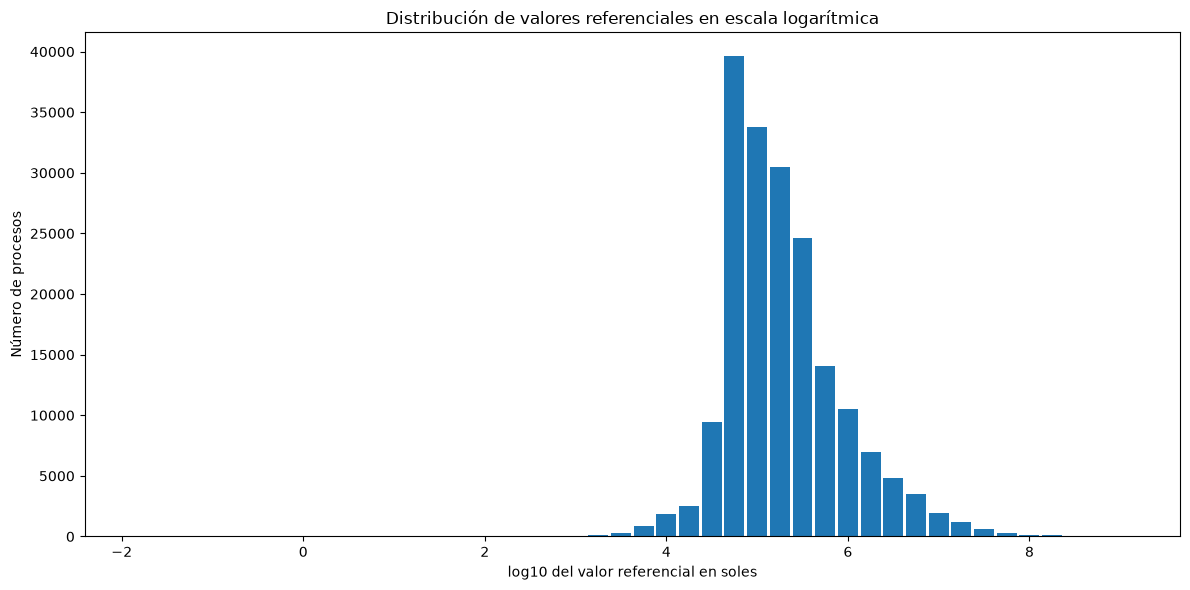

In [42]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    hist_montos_pd["bin"],
    hist_montos_pd["n_procesos"],
    width=0.22
)

ax.set_title("Distribución de valores referenciales en escala logarítmica")
ax.set_xlabel("log10 del valor referencial en soles")
ax.set_ylabel("Número de procesos")

plt.tight_layout()
plt.show()

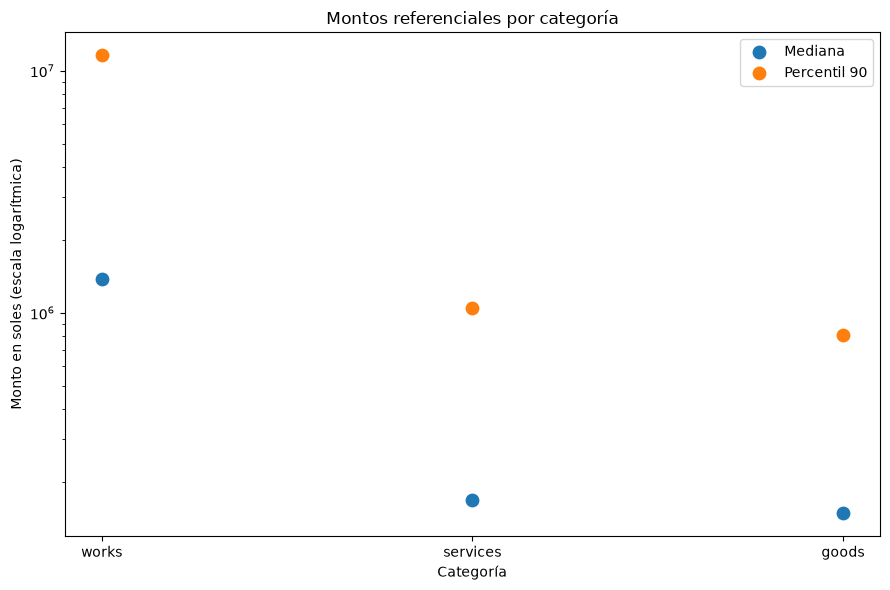

In [43]:
montos_categoria_pd = montos_categoria.toPandas()

fig, ax = plt.subplots(figsize=(9, 6))

x = range(len(montos_categoria_pd))

ax.scatter(
    x,
    montos_categoria_pd["mediana"],
    label="Mediana",
    s=80
)

ax.scatter(
    x,
    montos_categoria_pd["p90"],
    label="Percentil 90",
    s=80
)

ax.set_yscale("log")

ax.set_xticks(list(x))
ax.set_xticklabels(montos_categoria_pd["categoria"])

ax.set_title("Montos referenciales por categoría")
ax.set_xlabel("Categoría")
ax.set_ylabel("Monto en soles (escala logarítmica)")
ax.legend()

plt.tight_layout()
plt.show()

In [44]:
hist_montos_pd.to_csv(
    ARTIFACTS_DIR / "distribucion_montos_log.csv",
    index=False
)

montos_categoria_pd.to_csv(
    ARTIFACTS_DIR / "montos_por_categoria.csv",
    index=False
)

In [45]:
procesos.select(
    "release_id",
    "ocid",
    "proceso_id",
    "entidad",
    "procedimiento",
    "categoria",
    "valor_pen_valido",
    "fecha_pub"
).filter(
    F.col("valor_pen_valido").isNotNull()
).orderBy(
    F.desc("valor_pen_valido")
).show(10, truncate=False)

+-------------------------------------------------------------------+----------------------------------+----------+-------------------------------------------------------------------------------------+-------------------------+---------+----------------+-------------------+
|release_id                                                         |ocid                              |proceso_id|entidad                                                                              |procedimiento            |categoria|valor_pen_valido|fecha_pub          |
+-------------------------------------------------------------------+----------------------------------+----------+-------------------------------------------------------------------------------------+-------------------------+---------+----------------+-------------------+
|ocds-dgv273-seacev3-1150497-2025-12-13T10:09:26.335579-05:00       |ocds-dgv273-seacev3-1150497       |1150497   |AUTORIDAD NACIONAL DE INFRAESTRUCTURA                       

### Interpretación

Los valores referenciales presentan una distribución fuertemente asimétrica hacia la derecha.

El 89.65% de los procesos dispone de un valor referencial válido en soles. La mediana es aproximadamente S/ 195 mil, mientras que la media alcanza S/ 1.67 millones, más de ocho veces la mediana. Esto indica que una proporción pequeña de procesos de monto muy elevado incrementa considerablemente el promedio.

La asimetría también se observa en los percentiles. El 90% de los procesos tiene valores inferiores a S/ 1.89 millones, el 95% se encuentra por debajo de S/ 4.59 millones y el 99% por debajo de aproximadamente S/ 23.12 millones. Sin embargo, el percentil 99.9 alcanza cerca de S/ 191.76 millones y el máximo supera S/ 1.13 mil millones.

Las obras presentan montos sustancialmente mayores que las demás categorías. Su mediana es aproximadamente S/ 1.38 millones, frente a S/ 168.7 mil en servicios y S/ 148.6 mil en bienes. Por tanto, aunque las obras representan una proporción menor del número total de procesos, sus valores referenciales típicos son considerablemente superiores.

Debido a esta fuerte cola derecha, la mediana y los percentiles resultan más representativos que la media para describir un proceso típico. Asimismo, para la visualización se utiliza una escala logarítmica, que permite observar simultáneamente los procesos de montos pequeños, medianos y extremadamente altos sin eliminar estos últimos del análisis.

## 6. Estado de los procesos de contratación

**Pregunta:** ¿En qué estados se encuentran los procesos de contratación y qué proporción representan los procesos desiertos?

Se utiliza `estado_proceso`, que resume el estado detallado de los ítems que conforman cada proceso.

In [46]:
estados = (
    procesos
    .groupBy("estado_proceso")
    .agg(
        F.count("*").alias("n_procesos")
    )
    .withColumn(
        "porcentaje",
        F.round(
            F.col("n_procesos") / total_procesos * 100,
            2
        )
    )
    .orderBy(F.desc("n_procesos"))
)

estados.show(30, truncate=False)

+--------------------------------------------------+----------+----------+
|estado_proceso                                    |n_procesos|porcentaje|
+--------------------------------------------------+----------+----------+
|CONTRATADO                                        |131154    |62.53     |
|DESIERTO                                          |25268     |12.05     |
|CONVOCADO                                         |13577     |6.47      |
|NULO                                              |11874     |5.66      |
|CONSENTIDO                                        |10700     |5.1       |
|MIXTO                                             |6721      |3.2       |
|ADJUDICADO                                        |3395      |1.62      |
|RETROTRAIDO_POR_RESOLUCION                        |3150      |1.5       |
|CANCELADO                                         |2812      |1.34      |
|PENDIENTE_DE_REGISTRO_DE_EFECTO                   |280       |0.13      |
|APELADO                 

In [47]:
estado_anio = (
    procesos
    .groupBy("anio_pub", "estado_proceso")
    .agg(
        F.count("*").alias("n_procesos")
    )
)

totales_anio = (
    procesos
    .groupBy("anio_pub")
    .agg(
        F.count("*").alias("total_anio")
    )
)

estado_anio_pct = (
    estado_anio
    .join(totales_anio, "anio_pub")
    .withColumn(
        "porcentaje",
        F.round(
            F.col("n_procesos") / F.col("total_anio") * 100,
            2
        )
    )
    .orderBy("anio_pub", F.desc("n_procesos"))
)

estado_anio_pct.show(50, truncate=False)

+--------+--------------------------------------------------+----------+----------+----------+
|anio_pub|estado_proceso                                    |n_procesos|total_anio|porcentaje|
+--------+--------------------------------------------------+----------+----------+----------+
|2024    |CONTRATADO                                        |50926     |80109     |63.57     |
|2024    |DESIERTO                                          |8598      |80109     |10.73     |
|2024    |NULO                                              |4689      |80109     |5.85      |
|2024    |CONSENTIDO                                        |4295      |80109     |5.36      |
|2024    |MIXTO                                             |3889      |80109     |4.85      |
|2024    |CONVOCADO                                         |3775      |80109     |4.71      |
|2024    |ADJUDICADO                                        |1380      |80109     |1.72      |
|2024    |CANCELADO                               

### Interpretación

El estado predominante de los procesos es `CONTRATADO`, con 131,154 procesos, equivalentes al 62.53% del total. Le siguen `DESIERTO` con 12.05%, `CONVOCADO` con 6.47%, `NULO` con 5.66% y `CONSENTIDO` con 5.10%.

La distribución por año debe interpretarse considerando la fecha de corte de los datos. En 2024 y 2025, los procesos `CONVOCADO` representan 4.71% y 3.75%, respectivamente. En 2026 esta proporción aumenta hasta 13.53%, mientras que los procesos `CONTRATADO` disminuyen a 52.03%.

Esta diferencia no debe interpretarse directamente como una reducción en el éxito de las contrataciones de 2026. Debido a que el dataset llega hasta agosto de ese año y los estados corresponden a la situación observada en la fecha de corte, una mayor proporción de los procesos recientes todavía se encuentra abierta o en etapas intermedias.

Los procesos `DESIERTO` representan 12.05% del periodo completo. Este estado resulta especialmente relevante para la etapa posterior de minería de flujos, ya que permite definir naturalmente un evento binario —desierto o no desierto— para evaluar DGIM.

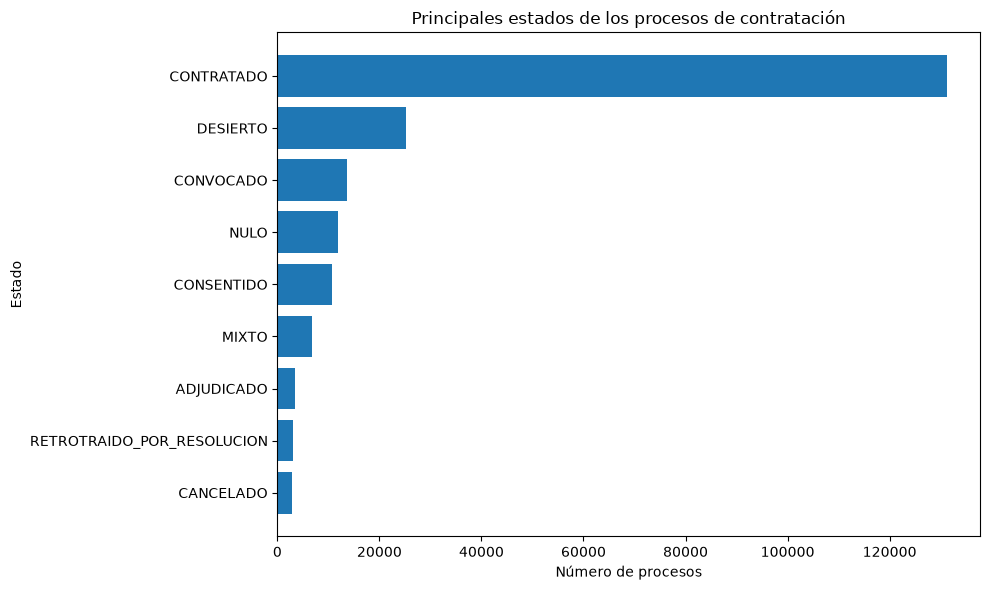

In [48]:
estados_pd = estados.toPandas()

estados_plot = (
    estados_pd
    .head(9)
    .sort_values("n_procesos", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    estados_plot["estado_proceso"],
    estados_plot["n_procesos"]
)

ax.set_title("Principales estados de los procesos de contratación")
ax.set_xlabel("Número de procesos")
ax.set_ylabel("Estado")

plt.tight_layout()
plt.show()

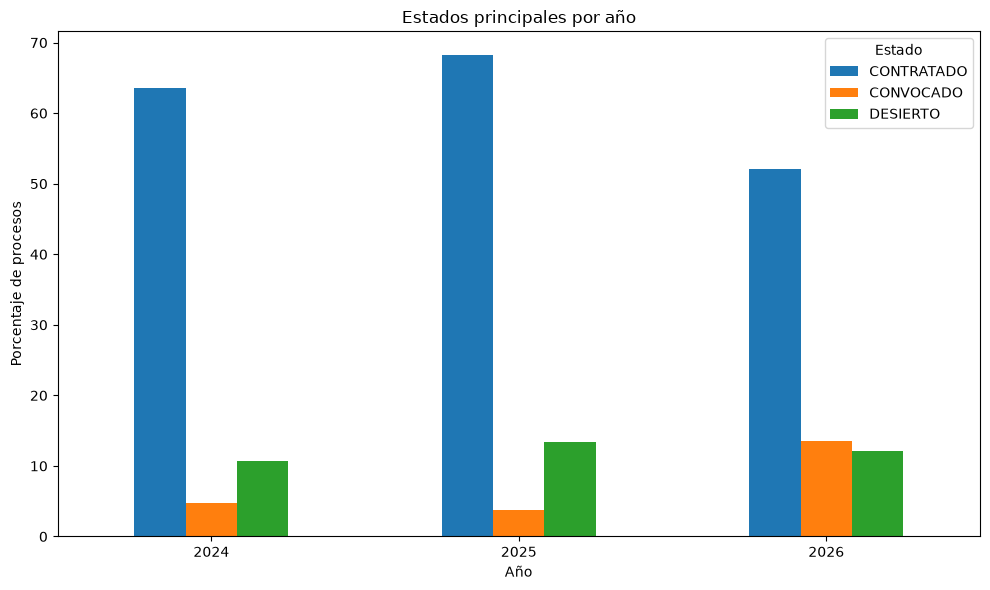

In [49]:
estados_seleccionados = ["CONTRATADO", "DESIERTO", "CONVOCADO"]

estado_anio_plot = (
    estado_anio_pct
    .filter(F.col("estado_proceso").isin(estados_seleccionados))
    .select("anio_pub", "estado_proceso", "porcentaje")
    .orderBy("anio_pub", "estado_proceso")
    .toPandas()
)

estado_anio_pivot = estado_anio_plot.pivot(
    index="anio_pub",
    columns="estado_proceso",
    values="porcentaje"
)

estado_anio_pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Estados principales por año")
plt.xlabel("Año")
plt.ylabel("Porcentaje de procesos")
plt.xticks(rotation=0)
plt.legend(title="Estado")
plt.tight_layout()
plt.show()

In [50]:
estados_pd.to_csv(
    ARTIFACTS_DIR / "estados_procesos.csv",
    index=False
)

estado_anio_plot.to_csv(
    ARTIFACTS_DIR / "estados_por_anio.csv",
    index=False
)